# Proton fluence to a signed magnetic-field map


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 从观测到恢复目标：证据卡

观测文件为 `data/raw_data.npz`（已读取实际NPZ header）：`x`，shape `(1, 200, 200)`，dtype `<f8`：Object-plane x coordinate; cm; varies on the first spatial axis；`y`，shape `(1, 200, 200)`，dtype `<f8`：Object-plane y coordinate; cm; varies on the second spatial axis；`fluence`，shape `(1, 200, 200)`，dtype `<f8`：Simulated detected proton counts per demagnified pixel; counts/pixel。未知量为两分量路径积分横向磁场，G cm。

获取模型：Lorentz冲量改变质子输运映射；Jacobian守恒将均匀入射通量变为观测fluence。

如何恢复：src.solvers.reconstruct：identity势初始化、非线性输运势迭代，再经Lorentz符号转换；linear_poisson为对照。

GT与评价：GT为生成观测前定义的模拟物理未知量，不是恢复结果。

已有实验和图：cell6完整逆解；8六图含fluence/双符号真值/新解、线性比较、前向射线一致性及迭代。

执行限制：已找到本地恢复路径（可能经review/run_experiments包装）；存档执行输出不等于本次重新运行。本页保留1个含PNG输出的代码cell；本次静态核查没有重跑、补图或新增实验。作者既有模拟场是真值；beam沿-Z的符号由独立Lorentz积分验证，不能只按图像模长评价。

<!-- inverse-evidence-audit:20261026:end -->


## 1. Problem

A proton-count image measures the density of deflected particles, rather than their individual trajectories. We recover **both transverse path-integrated magnetic components** on the full200×200 supplied grid. This notebook actively runs the complete selected400000-update inverse using the cleaned local implementation. It never substitutes an archived reconstruction for that run.

The experiment is an existing author simulation, not a new synthetic observation or a measured plasma. The selected native example includes a separate actual field array. This allows absolute, signed, component-wise evaluation. The author paper [Bott et al., JPP83,905830614(2017)](https://doi.org/10.1017/S0022377817000939) studies several contrast regimes; this bound example tests its nonlinear potential-map inverse. Stochastic-field energy spectra are not computed here because this isolated nonhomogeneous object does not meet their isotropy/homogeneity assumptions. No figures or numbers from other paper acquisitions are represented as this experiment.

The two principal comparisons are the independently executed original nonlinear method and a fresh weak-contrast Poisson inversion. Additional diagnostics test transport injectivity, count conservation, numerical trajectory, ray-bin discretization and physical handedness.

In [1]:
import os, sys, platform, time, json, subprocess
from pathlib import Path
for name in ['OMP_NUM_THREADS','OPENBLAS_NUM_THREADS','MKL_NUM_THREADS','NUMEXPR_NUM_THREADS']:
    os.environ[name]='1'
TASK=Path.cwd().resolve()
for candidate in [TASK,*TASK.parents]:
    if (candidate/'src/preprocessing.py').is_file() and (candidate/'data/raw_data.npz').is_file():
        TASK=candidate
        break
sys.path.insert(0,str(TASK))
import numpy as np
import scipy
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from src.preprocessing import load_observations
from src.solvers import reconstruct, linear_poisson
from src.physics_model import ray_forward_fluence
from src.visualization import make_figures, field_metrics
from src.main import save_diagnostics
REF=TASK/'notebooks/reference_outputs'
PRIVATE=next(parent for parent in TASK.parents if parent.name == 'tasks').parent.parent/'imaging-101-maintainer/research_batch7_20261022/groups/physics_materials/proton'
FIGURE_DIR=PRIVATE/'figures'
print('Actual kernel:',sys.executable)
print('Python',platform.python_version(),'NumPy',np.__version__,'SciPy',scipy.__version__)
print('CPU threads:',os.environ['OPENBLAS_NUM_THREADS'])

Actual kernel: D:\yan1\agent\AutoSkill\imaging-101-maintainer\research-runtime\Scripts\python.exe
Python 3.11.11 NumPy 2.4.6 SciPy 1.17.1
CPU threads: 1


## 2. Data

The raw array contains unchanged author counts and unchanged object-plane x/y coordinates. Every pixel is retained. The pixel-centre interval is−0.0995 to0.0995cm on each axis. Coordinates are demagnified detector coordinates for the measured count image and initial object coordinates for the transport map. Uniform incident counts are fixed by the measured mean, without access to the unknown object.

The actual magnetic truth and the original-method result are hidden maintainer assets, used below only for evaluation and labeled comparisons. The original field is the source's actual400000-update run on these exact observations. Its physical conversion constants and signs are preserved. The original stopping condition reaches its update budget rather than its0.001 residual tolerance.

In [2]:
data=load_observations()
with np.load(TASK/'evaluation/ground_truth.npz',allow_pickle=False) as archive:
    actual_truth=archive['reconstruction'][0].copy()
with np.load(REF/'upstream.npz',allow_pickle=False) as archive:
    original_field=archive['reconstruction'][0].copy()
print('Raw shapes/dtypes:',{key:(value.shape,str(value.dtype)) for key,value in data.items()})
print('Total counts:',data['fluence'].sum(),'incident counts/pixel:',data['fluence'].mean())
print('Actual truth and independent original run are distinct labeled arrays.')

Raw shapes/dtypes: {'x': ((200, 200), 'float64'), 'y': ((200, 200), 'float64'), 'fluence': ((200, 200), 'float64')}
Total counts: 29354394.0 incident counts/pixel: 733.85985
Actual truth and independent original run are distinct labeled arrays.


## 3. Physics

Use a right-handed laboratory frame with X right, Y up and Z out of the detector. The beam points into the detector, along negative laboratory Z. This resolves the source's “z into screen” convention: its beam direction and its two displayed image axes do **not** constitute a right-handed triple. For positive charge q, proton mass mp and light speed c,

$$\mathbf w=\frac{q}{m_pc}\widehat{\mathbf k}\times\mathbf b,\quad
\widehat{\mathbf k}=-\widehat{\mathbf Z},\quad
b_x=-\frac{m_pc}{q}w_y,\quad b_y=\frac{m_pc}{q}w_x.$$

The impulse w is in cm/s; b is a beam-path field integral in G cm. An independent positive-Bx Lorentz trajectory, tested separately from the conversion code, gives negative displayed-y deflection and recovers+20G cm for100G over0.2cm. Reversing beam direction while keeping the field unchanged is an explicit physical control below, never an evaluation alignment.

With source distance ri, volume extent li, detector drift rs and positive speed v, define magnification M and the demagnified map T:

$$M=\frac{r_s+r_i+l_i/2}{r_i+l_i/2},\qquad
\mathbf T=\mathbf x+\frac{r_s}{Mv}\mathbf w=\nabla\Phi.$$

The mapping potential Phi has units cm². Conservation relates observed counts f to uniform incident counts f0:

$$f(\nabla\Phi)\det\nabla^2\Phi=f_0.$$

A convex potential gives an injective map. Normal zero deflection imposes the identity normal map at the image edges. Spatially resolved caustics would invalidate uniqueness of this single-map interpretation. The selected cgs conversion uses the rounded supplied speed and small-angle source model; it adds no relativistic gamma factor.

## 4. Method

We initialize the potential with the identity map, differentiate using the source's finite-difference stencils, impose normal Neumann gradients, and evaluate a bilinear observed-count interpolant at the mapped coordinates. The local executable update is

$$\Phi^{k+1}=\Phi^k+\Delta\tau\log\left[\frac{f(\nabla\Phi^k)|\det H^k|}{f_0}\right].$$

Here k is the zero-based update index, H is the discretized Hessian, and relaxation increment Δτ=1e−8cm². The mixed Hessian is zero at all four edges. Source absolute-determinant behavior is preserved; positivity is checked rather than assumed. The loop stops after updating when the pre-update log-residual Euclidean norm is below0.001, or after400000 updates. The returned mapping is the last pre-update gradient, matching the source's actual return order. No checkpoint is loaded.

The separate weak-contrast baseline linearizes the transport equation to a homogeneous-Neumann Poisson problem. It uses an explicit DCT diagonalization and the same field conversion. It is computed freshly below.

The following full run is intentional and may take tens of minutes on one CPU thread. No cache-preview mode is used.

In [3]:
started=time.perf_counter()
fresh=reconstruct(data['x'],data['y'],data['fluence'])
print('Fresh full reconstruction seconds:',time.perf_counter()-started)
print('Updates:',fresh['iterations'],'stopping:',fresh['stopping'])
print('Final residual norm:',fresh['residual_norm'][-1])
print('Nonpositive determinant pixels across all updates:',fresh['negative_determinant_count'])
save_diagnostics(fresh,REF/'fresh.npz')
linear=linear_poisson(data['x'],data['y'],data['fluence'])
out=TASK/'output';out.mkdir(exist_ok=True)
np.savez_compressed(out/'reconstruction.npz',reconstruction=fresh['reconstruction'][None])
judge=subprocess.run([sys.executable,str(TASK/'evaluation/judge.py'),'--prediction',str(out/'reconstruction.npz'),'--report',str(out/'judge_report.json')],capture_output=True,text=True,shell=False)
print('Standalone Judge child returncode:',judge.returncode)
assert judge.returncode==0,judge.stderr
print((out/'judge_report.json').read_text(encoding='utf-8'))

Fresh full reconstruction seconds: 1345.4792054999998
Updates: 400000 stopping: maximum_steps
Final residual norm: 0.3668422103144939
Nonpositive determinant pixels across all updates: 0


Standalone Judge child returncode: 0
{
  "status": "pass",
  "passed": true,
  "metrics": {
    "Bx_ncc": 0.9998954769866146,
    "Bx_nrmse": 0.0034684819218189743,
    "By_ncc": 0.9998972142030367,
    "By_nrmse": 0.0034326363521011683
  },
  "thresholds": {
    "Bx_ncc": {
      "comparison": "greater_equal",
      "boundary": 0.8999059292879528
    },
    "Bx_nrmse": {
      "comparison": "less_equal",
      "boundary": 0.003815330114000872
    },
    "By_ncc": {
      "comparison": "greater_equal",
      "boundary": 0.8999074927827331
    },
    "By_nrmse": {
      "comparison": "less_equal",
      "boundary": 0.0037758999873112853
    }
  },
  "errors": []
}


## 5. Results

All following figures use freshly computed local arrays for the selected reconstruction and the linear comparison. “Independent original” means the separate unmodified upstream run, not a paper number. “Actual author field” is genuine supplied simulation truth, not an estimated reference.

Field scores use full-domain component-wise cosine NCC and dynamic-range NRMSE. The original/fresh comparison uses no shift, sign or gain fitting. The forward analysis bins equal-weight incident rays using the same stated physical constants. Refinement from4² to32² rays per pixel exposes discretization effects. It is a distinct numerical check from the inverse differential mass residual.

The stored count image was not newly generated here, and the author did not supply its original particle generator. Its approximate-model prediction from the actual field is not claimed to match the stored noise exactly. The resulting discrepancy remains visible. Count-image NRMSE and field NRMSE are separately named and are never interchanged.

{
  "field": {
    "Upstream nonlinear": {
      "Bx": {
        "ncc": 0.9998954769866146,
        "nrmse": 0.0034684819218189743,
        "relative_l2": 0.022372646096340557
      },
      "By": {
        "ncc": 0.9998972142030367,
        "nrmse": 0.0034326363521011683,
        "relative_l2": 0.022141432480846903
      }
    },
    "Fresh nonlinear": {
      "Bx": {
        "ncc": 0.9998954769866146,
        "nrmse": 0.0034684819218189743,
        "relative_l2": 0.022372646096340557
      },
      "By": {
        "ncc": 0.9998972142030367,
        "nrmse": 0.0034326363521011683,
        "relative_l2": 0.022141432480846903
      }
    },
    "Linear Poisson": {
      "Bx": {
        "ncc": 0.7651802686135205,
        "nrmse": 0.10285743635903173,
        "relative_l2": 0.6634582719204934
      },
      "By": {
        "ncc": 0.7651603421604039,
        "nrmse": 0.10285897428405488,
        "relative_l2": 0.6634681919526694
      }
    }
  },
  "ray_forward": {
    "truth4": {
      "

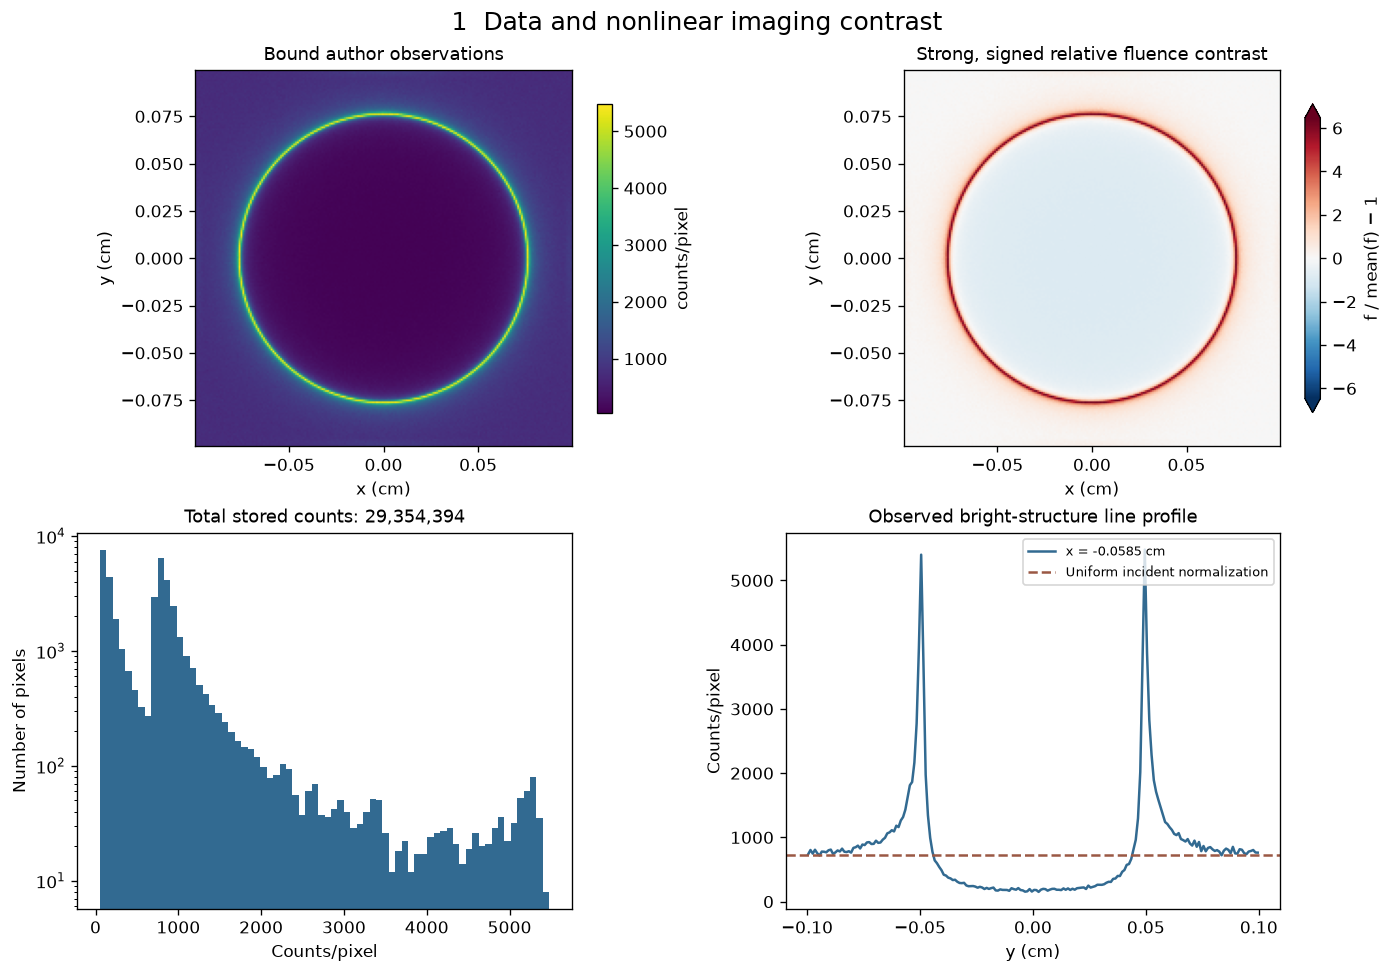

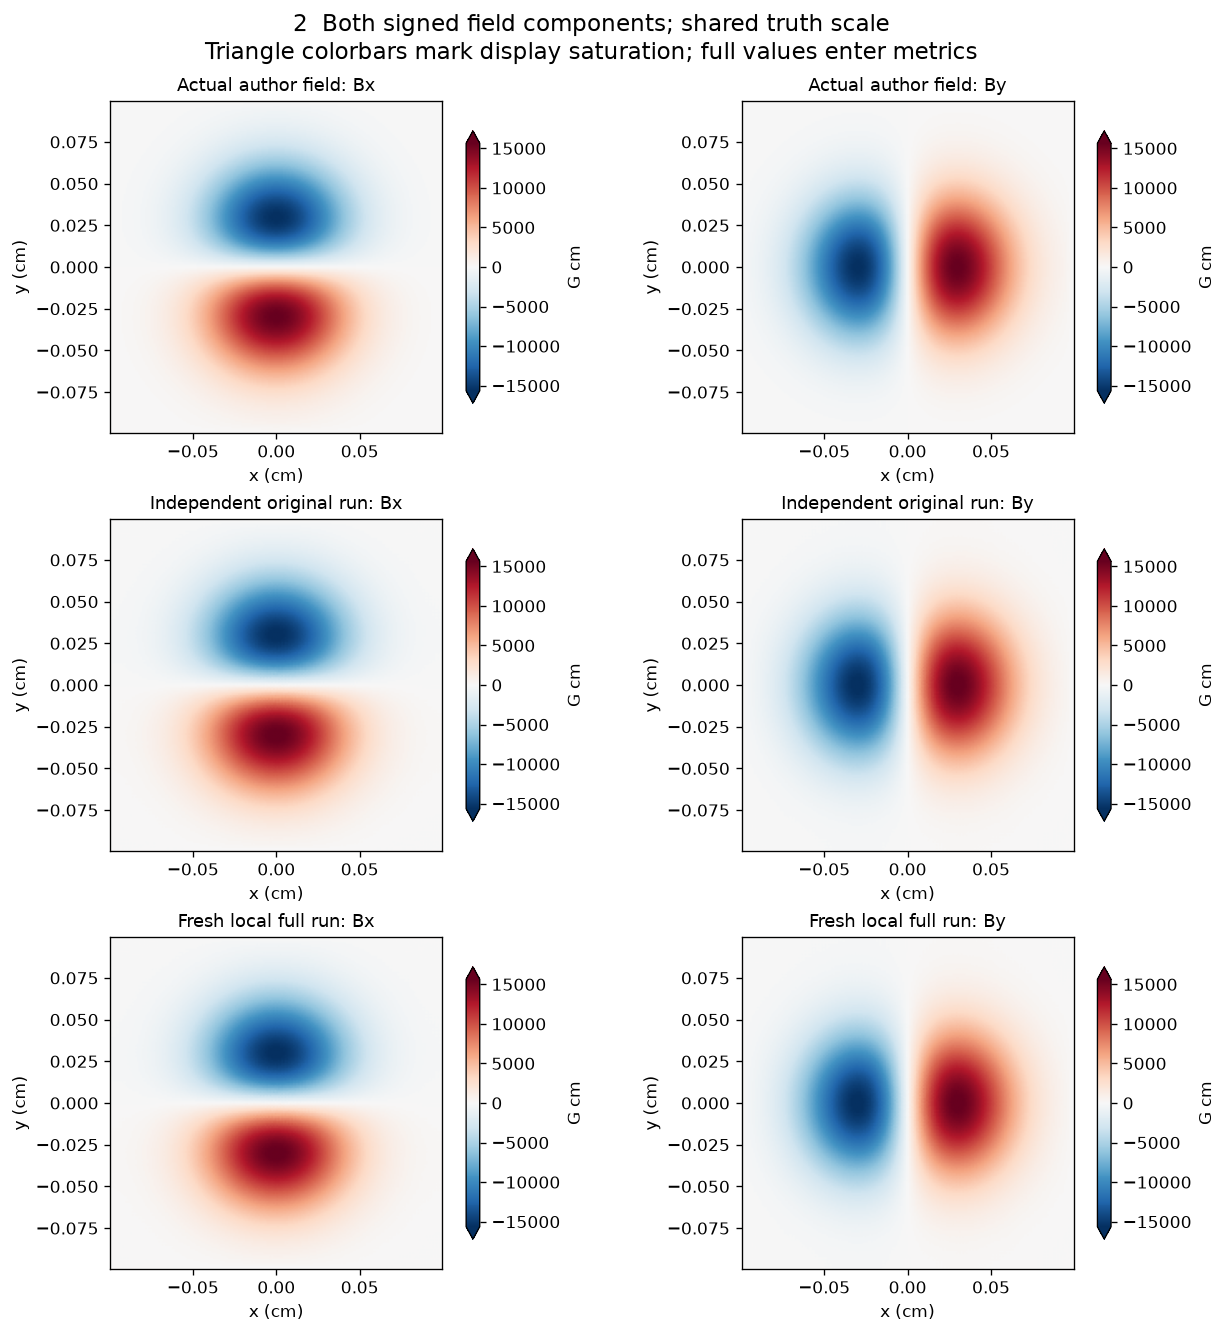

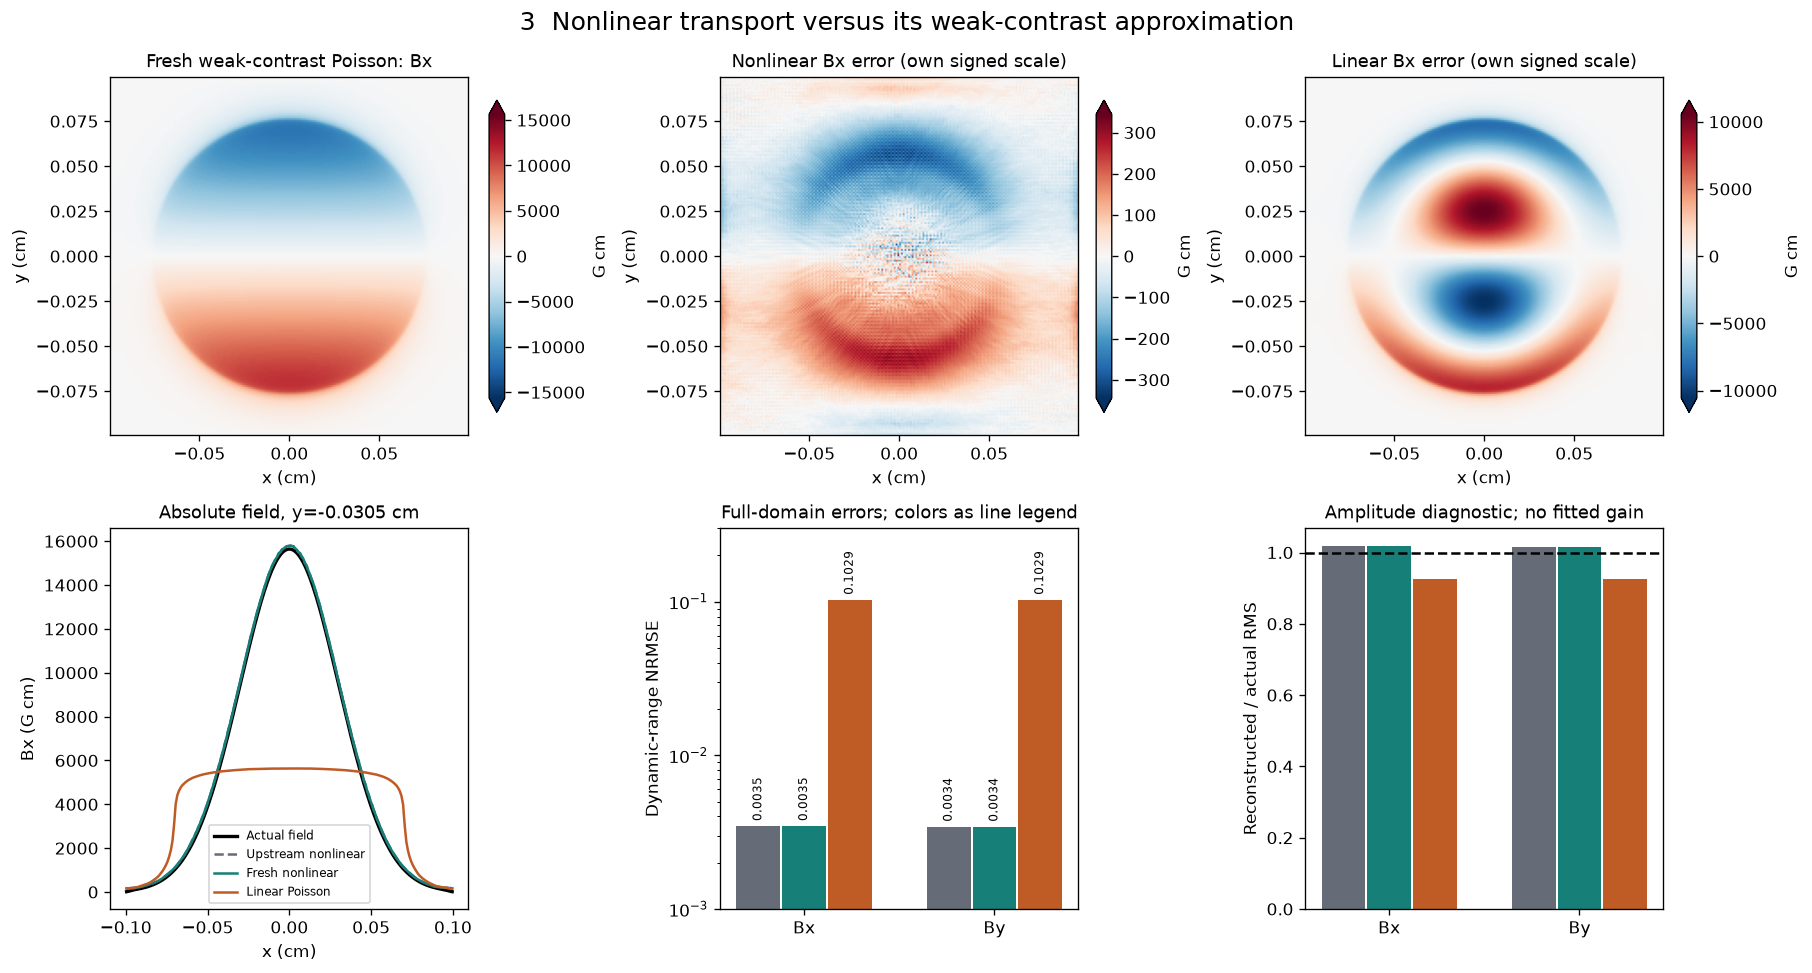

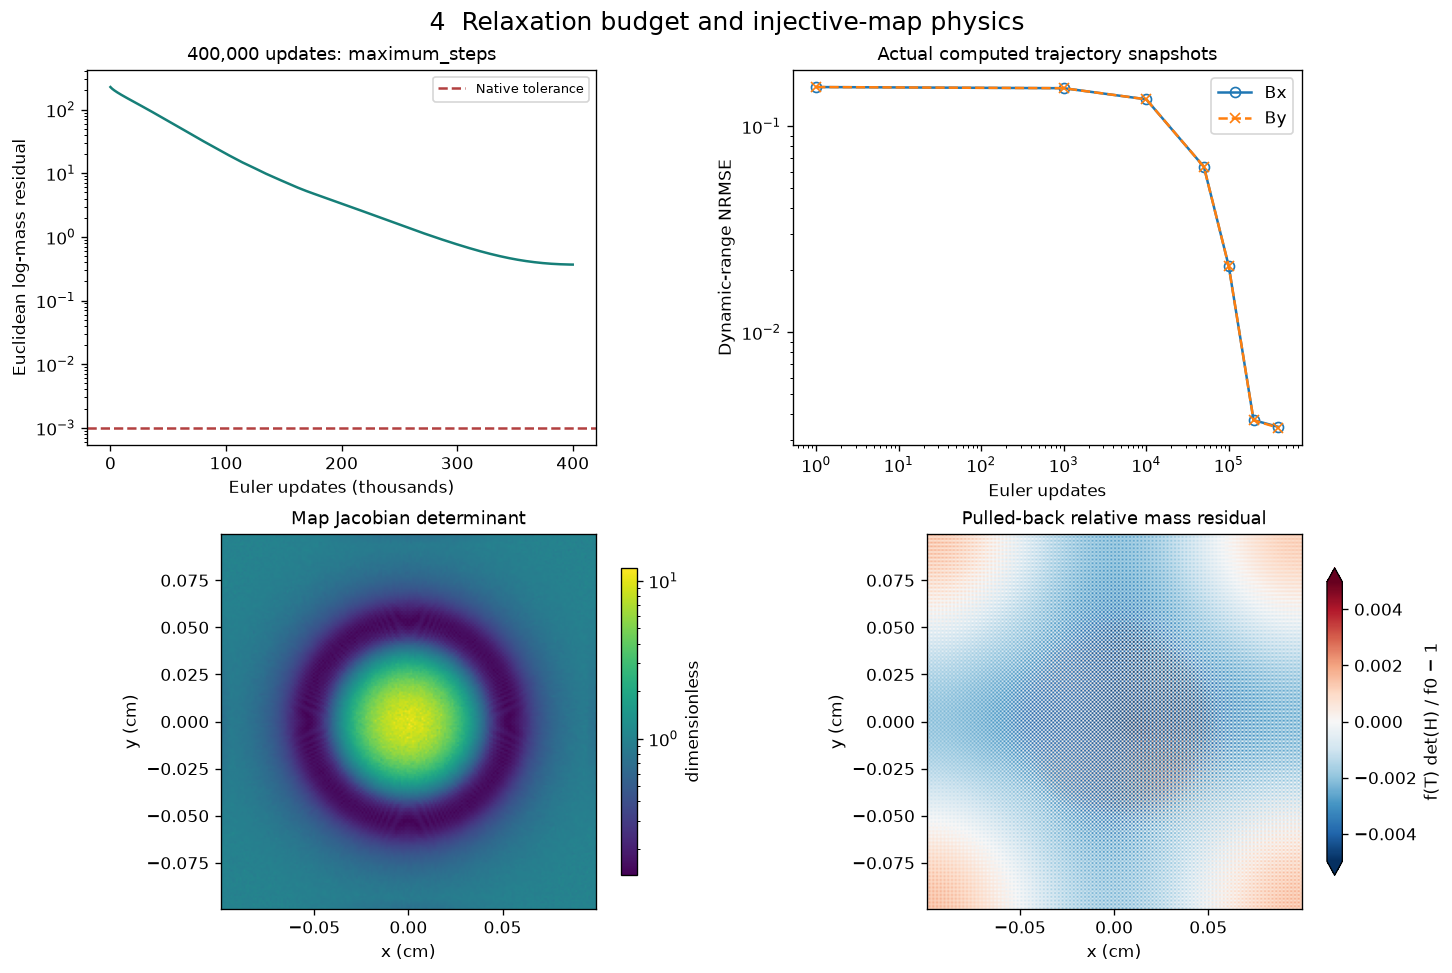

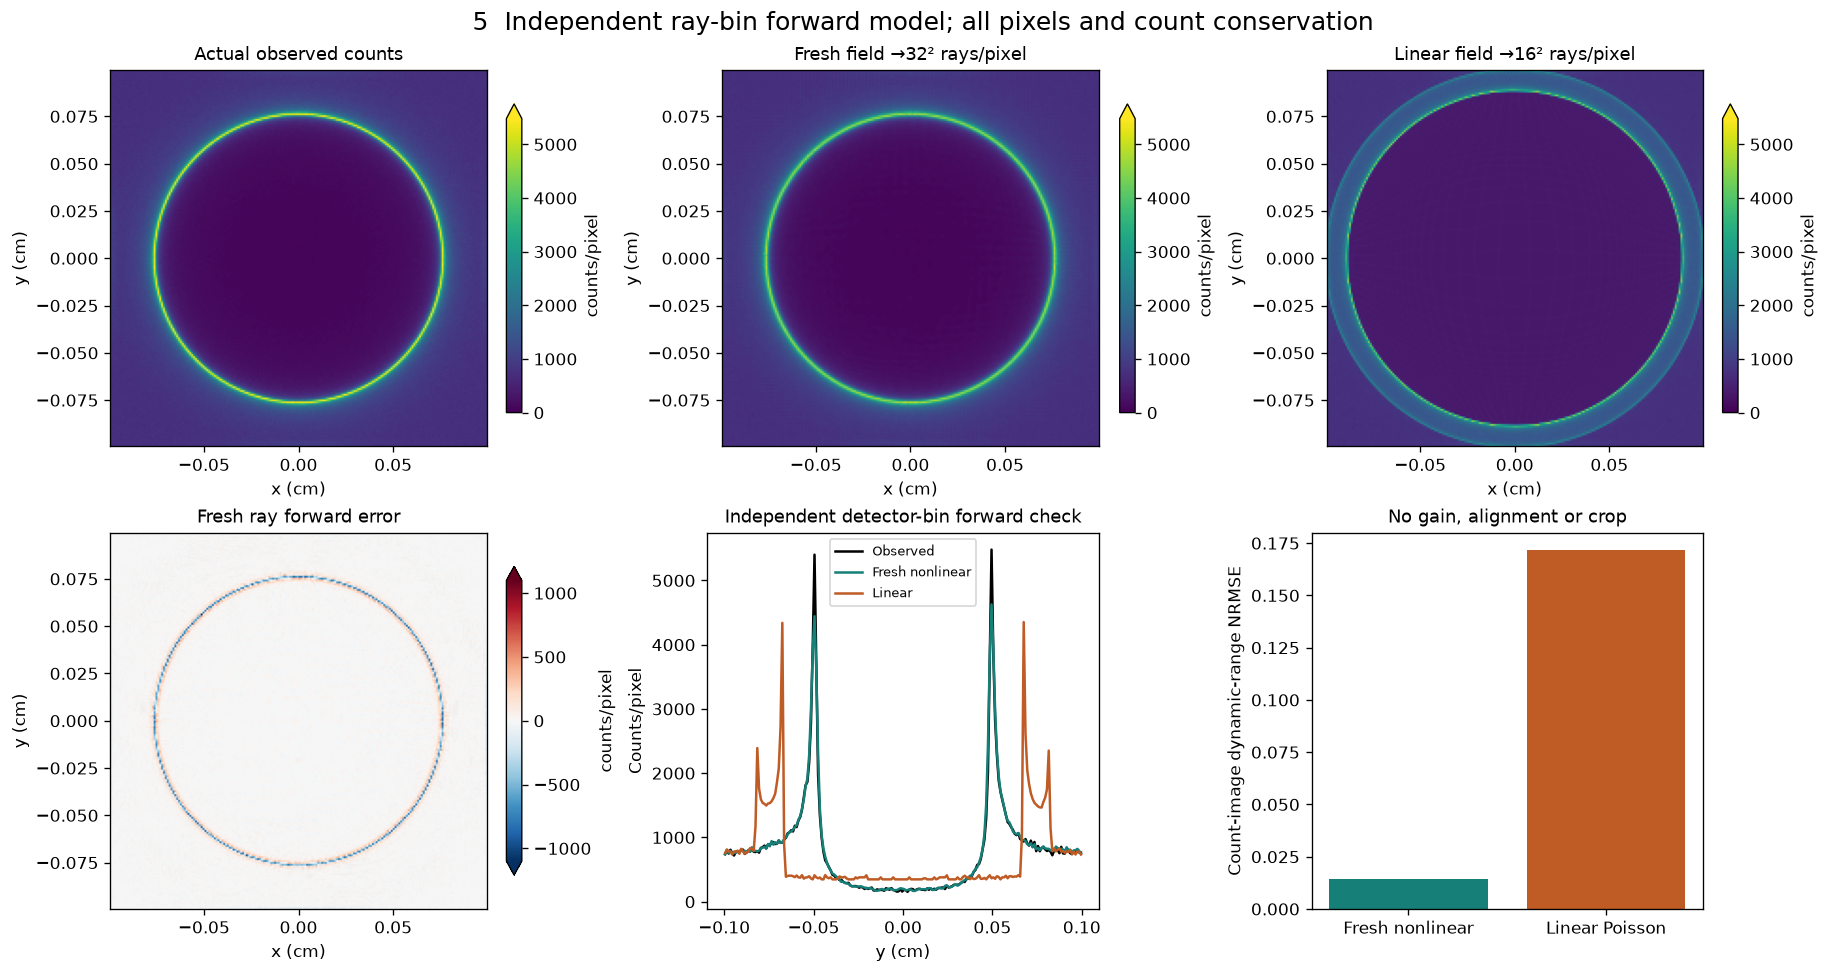

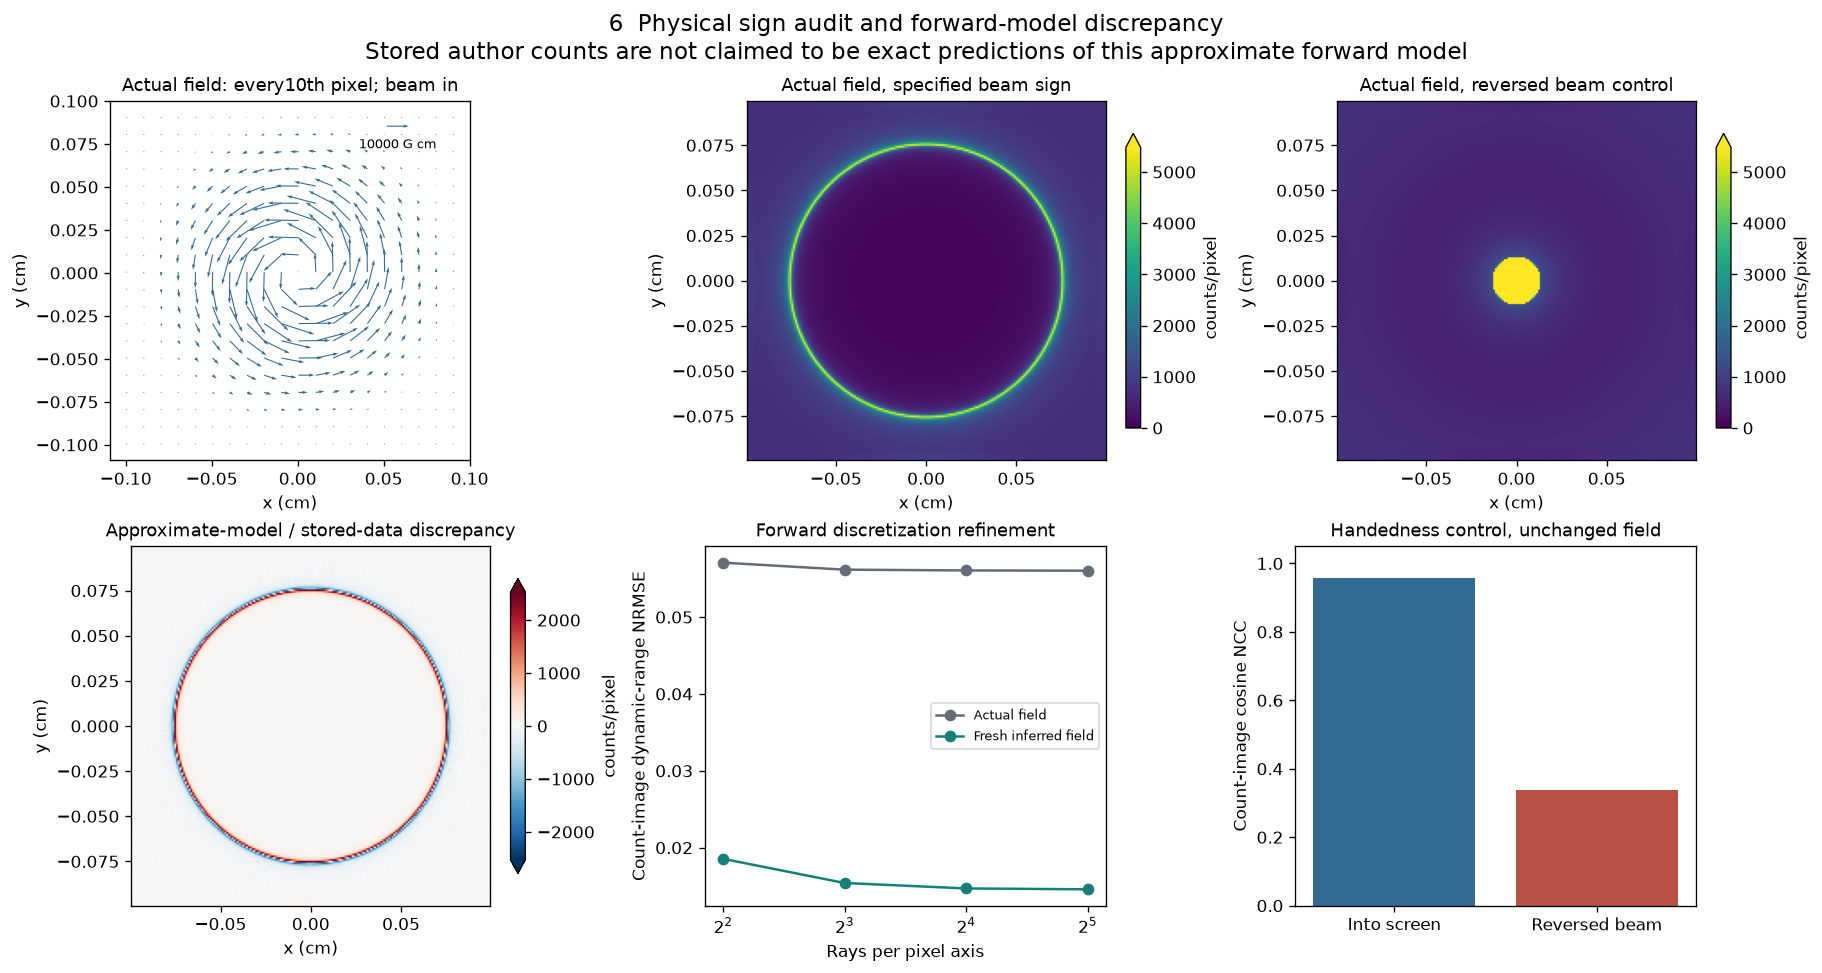

PNG/SVG/PDF and paired numeric source: D:\yan1\agent\AutoSkill\imaging-101-maintainer\research_batch7_20261022\groups\physics_materials\proton\figures


In [4]:
forwards={}
for prefix,field in [('truth',actual_truth),('fresh',fresh['reconstruction'])]:
    for n in [4,8,16,32]:
        forwards[f'{prefix}{n}']=ray_forward_fluence(data['x'],data['y'],field,float(data['fluence'].mean()),subpixels=n)
forwards['wrong32']=ray_forward_fluence(data['x'],data['y'],actual_truth,float(data['fluence'].mean()),subpixels=32,beam_direction=1)
forwards['linear16']=ray_forward_fluence(data['x'],data['y'],linear,float(data['fluence'].mean()),subpixels=16)
figures,metrics=make_figures(data,actual_truth,original_field,fresh,linear,forwards,FIGURE_DIR)
print(json.dumps(metrics,indent=2))
for fig in figures:
    display(fig)
    plt.close(fig)
print('PNG/SVG/PDF and paired numeric source:',FIGURE_DIR)

Figures1–3 show the bound acquisition, both signed physical components, full-domain errors and the failure of a weak-contrast approximation at the observed contrast. Original and fresh fields share the actual-field color scale; triangles indicate display saturation, while metrics retain full values. Separate error-map ranges are explicitly labeled.

Figure4 reports the actual update trajectory, including field error at computed snapshots. Snapshot indices are zero-based: index1000 follows1001 updates. The complete scalar trajectory replaces the source's hundreds of individual checkpoint images without discarding a comparison method. Figure5 checks the inferred fields with an independent ray-bin forward discretization. Figure6 fixes coordinate handedness by a physically reversed-beam control and shows convergence of the ray-bin discretization. Count-image panels share the observed-image color range; triangles mark any display saturation.

The numerical source for every panel, all precision metrics, and the figure-to-array index are exported alongside the PNG/SVG/PDF figures. The final notebook retains its actual executed outputs.

## 6. Conclusion

The selected experiment reconstructs two signed spatial magnetic integrals using a local nonlinear transport solver. The nonlinear and linear methods are separately executed, and agreement with the independent original run is distinct from agreement with actual simulated truth.

The retained limitations matter: the native update budget is reached before its residual tolerance; the source's small-angle/finite-object model is approximate; the stored count generator is unavailable; and true-field forward counts exhibit a model/data discrepancy that is not removed by gain fitting. Positive Jacobians and physical sign tests support this bound injective interpretation, but do not establish uniqueness after caustics or justify a full three-dimensional magnetic field inference.

In [5]:
print('Final fresh component metrics:',json.dumps(metrics['field']['Fresh nonlinear'],indent=2))
print('Minimum determinant:',float(fresh['det'].min()))
print('RMS relative differential mass residual:',float(np.sqrt(np.mean(np.expm1(fresh['Fn'])**2))))
print('Into-screen vs reversed-beam count NCC:',metrics['ray_forward']['truth32']['ncc'],metrics['ray_forward']['wrong32']['ncc'])
print('Kernel executable:',sys.executable)
print('Notebook completed after active full reconstruction, independent evaluation and all six computed figures.')

Final fresh component metrics: {
  "Bx": {
    "ncc": 0.9998954769866146,
    "nrmse": 0.0034684819218189743,
    "relative_l2": 0.022372646096340557
  },
  "By": {
    "ncc": 0.9998972142030367,
    "nrmse": 0.0034326363521011683,
    "relative_l2": 0.022141432480846903
  }
}
Minimum determinant: 0.1363272366089941
RMS relative differential mass residual: 0.0018314074198153682
Into-screen vs reversed-beam count NCC: 0.9578156617066599 0.33681138466420313
Kernel executable: D:\yan1\agent\AutoSkill\imaging-101-maintainer\research-runtime\Scripts\python.exe
Notebook completed after active full reconstruction, independent evaluation and all six computed figures.
